# Exploración y primeros modelos en cintas transportadoras
**Patrick · entrega de modelado temprano · ejecución local.**

Este notebook presenta un trabajo **ejecutado**: datos revisados, limpieza, evaluación agrupada, referencias, transferencia de aprendizaje e iteraciones guiadas por validación. Los scripts auxiliares implementan los experimentos; aquí se reconstruyen sus resultados guardados sin volver a entrenar.

**Pregunta inicial:** ¿podemos clasificar una imagen de coal como flujo normal, bloque grande o perno? La salida normal/riesgo se deriva de esas tres clases. No entrenamos un detector espacial: las etiquetas actuales no contienen bounding boxes. Iron participa de la exploración; no se inventan etiquetas para entrenar con sus carpetas.

Objetivos de la pauta: **(1)** exploración y descripción que orientan decisiones y **(2)** primeros modelos, dificultades, aprendizajes y ajustes respaldados por resultados.

## 1. Cómo ejecutar y qué se necesita
Desde la raíz del repositorio: `python -m pip install -r notebooks/patrick/requirements.txt`. Para reproducir exactamente el entorno local, consultar `requirements-resolved.txt` y el README de esta carpeta. No se reinstala CUDA ni se requiere GPU para leer los resultados.

Se necesitan los scripts de esta carpeta y los artefactos locales `data/processed/patrick_v1`, `data/results/patrick_v1` y `data/weights/patrick_v1`. Los datos y pesos están excluidos de Git: clonar el repositorio no los descarga. El README incluye comandos para reconstruirlos desde raw.

Ejecutar todas las celdas **lee resultados y verifica consistencia**; el entrenamiento se solicita explícitamente por CLI. El notebook se ha probado con kernel nuevo local; el montaje de Drive y la ejecución en Colab no se han verificado. En Colab deben resolverse rutas y dependencias en esa sesión, sin presuponer estado del setup anterior.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Image as DisplayImage

# Resolver desde la raíz o desde notebooks/patrick, sin rutas personales fijas.
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p / 'notebooks/patrick/modeling.py').exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Abra el notebook dentro del clon del repositorio.')
sys.path.insert(0, str(PROJECT_ROOT / 'notebooks/patrick'))
from study_data import PROC, RESULTS, FIG, CLASSES, SPANISH, digest
from modeling import summarize

required = [PROC/'inventory.csv', PROC/'coal_manifest.csv', RESULTS/'final_test.json']
for p in required:
    if not p.exists():
        raise FileNotFoundError(f'Falta {p}. Vea los comandos de reproducción en README.md.')
inventory = pd.read_csv(PROC/'inventory.csv')
quality = pd.read_csv(PROC/'quality.csv')
coal = pd.read_csv(PROC/'coal_manifest.csv')
protocol = json.loads((PROC/'protocol.json').read_text())
final = json.loads((RESULTS/'final_test.json').read_text())
selection = final['selection']
selected = selection['run']
run_dir = RESULTS/'runs'/selected
comparison = pd.read_csv(RESULTS/'validation_comparison.csv')

def show(path, width=1000):
    display(DisplayImage(filename=str(path), width=width))

pd.set_option('display.max_columns', 20)
print('Python:', sys.version.split()[0])
print('Intérprete:', sys.executable)
print('Proyecto:', PROJECT_ROOT.name)
print('Versión de datos:', PROC.name)
print('Lectura de resultados, sin entrenamiento automático.')

Python: 3.12.4
Intérprete: /Users/patrick/code/master_proyecto_final/afg-cv-mining-conveyor-belts/.venv/bin/python
Proyecto: afg-cv-mining-conveyor-belts
Versión de datos: patrick_v1
Lectura de resultados, sin entrenamiento automático.


## 2. Qué existe y qué falta
Las carpetas de coal proporcionan etiquetas de **imagen completa**; no cajas. Iron contiene imágenes ordenables mediante el índice numérico del nombre, sin anotaciones locales por fotograma. Un nombre como `wood` no garantiza presencia de madera en cada imagen.

Inventariamos los originales y los contrastamos por SHA-256 con la auditoría previa. Se decodificó todo coal y una muestra temporal de 24 imágenes por cada carpeta de iron. El resto de iron pasó lectura de cabecera y hash; no se certifica su decodificación completa. No se revisaron visualmente todas las imágenes.

In [2]:
dataset_summary = inventory.groupby('dataset').agg(
    imagenes=('path','size'), bytes=('bytes','sum'),
    ancho_min=('width','min'), ancho_max=('width','max'),
    alto_min=('height','min'), alto_max=('height','max'), carpetas=('group','nunique'))
dataset_summary['MiB'] = dataset_summary['bytes'] / 2**20
display(dataset_summary.drop(columns='bytes').round(2))
display(pd.crosstab(inventory.loc[inventory.dataset=='coal','label'],
                    inventory.loc[inventory.dataset=='coal','original_split']))
print('Formatos:', inventory.groupby('dataset')['format'].unique().to_dict())
print('Campos sin etiqueta semántica en iron:', int((inventory.label=='unlabeled').sum()))
print('Archivos vacíos:', int((inventory.bytes==0).sum()))

,imagenes,ancho_min,ancho_max,alto_min,alto_max,carpetas,MiB
dataset,,,,,,,
coal,4800,416,416,416,416,6,346.04
iron,19211,1280,1280,720,720,12,1389.31


original_split,test,train
label,,
Normal Coal Flow,300,1300
Oversized Coal,300,1300
Rock Bolts,300,1300


Formatos: {'coal': <StringArray>
['JPEG']
Length: 1, dtype: str, 'iron': <StringArray>
['JPEG']
Length: 1, dtype: str}
Campos sin etiqueta semántica en iron: 19211
Archivos vacíos: 0


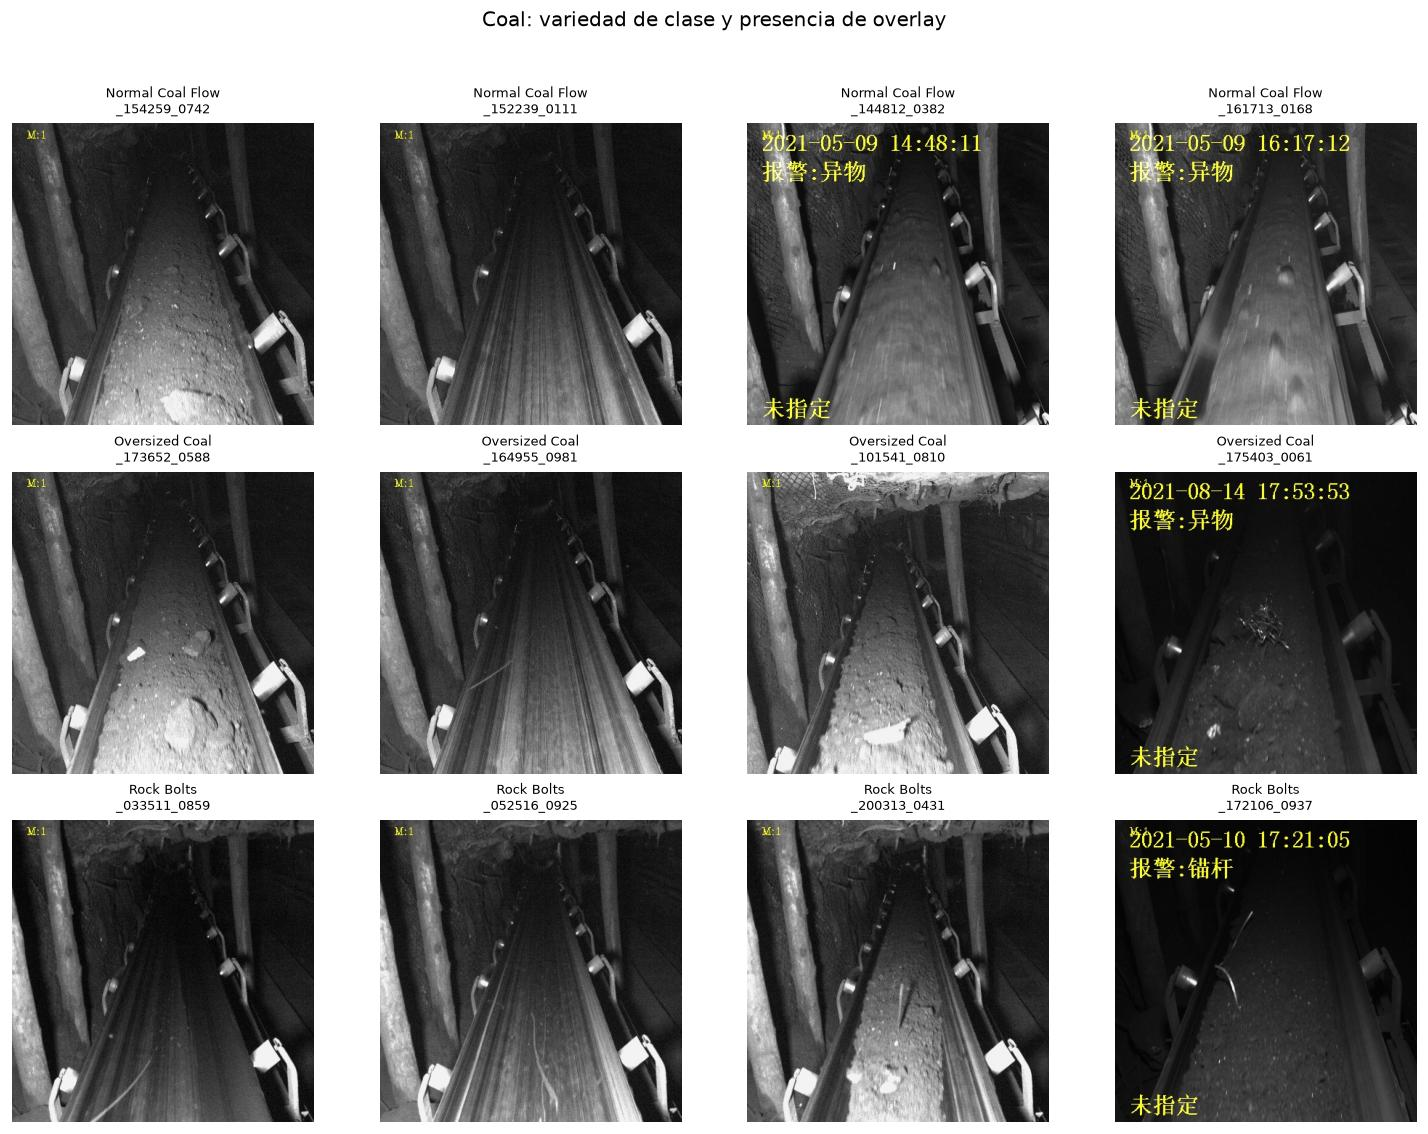

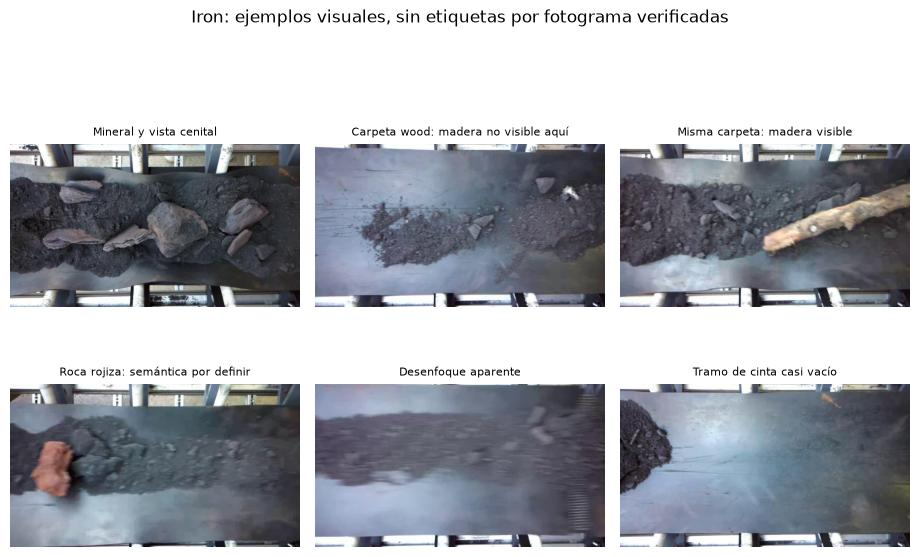

In [3]:
show(FIG/'coal_gallery.jpg', 1050)
show(FIG/'iron_compact.jpg', 1050)

**Lectura visual.** Coal presenta vistas en perspectiva, imágenes oscuras y texto sobreimpreso. Iron presenta vista cenital, color, cinta vacía, madera visible en algunos tramos y desenfoque. Una roca grande aparente no demuestra un umbral físico de sobretamaño: falta escala y criterio operacional. La procedencia planta/laboratorio y los FPS no se deducen solo de la apariencia.

Dentro de iron los índices consecutivos sugieren fotogramas relacionados; no representan observaciones independientes. Las discontinuidades se documentan como saltos de índices, no como segundos ni prueba automática de archivos perdidos.

In [4]:
iron_sequences = []
for group, g in inventory[inventory.dataset=='iron'].groupby('group'):
    frames = np.sort(g.path.str.extract(r'/(\d+)-', expand=False).astype(int).to_numpy())
    gaps = np.diff(frames)
    iron_sequences.append({'secuencia':Path(group).name.replace('boardcamera_iron_ore','iron'),
        'imagenes':len(g),'indice_min':int(frames.min()),'indice_max':int(frames.max()),
        'saltos_mayores_a_1':int((gaps>1).sum())})
display(pd.DataFrame(iron_sequences))

,secuencia,imagenes,indice_min,indice_max,saltos_mayores_a_1
0,iron,5740,5726,27663,1
1,iron_2,1512,1806,3317,0
2,iron_3,1848,3640,5487,0
3,iron_4,1134,2702,3835,0
4,iron_5,1008,12152,13159,0
5,iron_6,2265,4309,6573,0
6,iron_7_wood,1211,1964,3265,1
7,iron_7_wood_2,1153,2106,3258,0
8,iron_7_wood_3,1299,1868,3166,0
9,iron_canga,790,1486,2275,0


## 3. Calidad y relaciones descriptivas
El brillo es el promedio de intensidad en escala de grises [0,255]; el contraste es su desviación estándar. La nitidez es la varianza del Laplaciano después de llevar a 160×160: mide cambios locales, pero también responde a textura y overlays. No equivale a una medida física de enfoque.

Comparamos media, mediana, cuartiles e IQR y exploramos asociaciones. Las imágenes oscuras o borrosas **no se eliminan automáticamente**: representan parte del problema. En iron la muestra temporal sirve para explorar, no para inferir prevalencia de anomalías ni independencia estadística.

gray_mean                                            gray_std          \
            count     mean     std   median     min      max    count    mean   
dataset                                                                         
coal         4800   64.199  23.409   69.672  16.672  128.242     4800  47.382   
iron          288  112.015  15.594  113.443  64.584  141.523      288  50.644   

                         ... dark_fraction                    bright_fraction  \
            std  median  ...           std median  min    max           count   
dataset                  ...                                                    
coal     13.247  49.430  ...         0.203  0.196  0.0  0.865            4800   
iron      3.342  50.921  ...         0.012  0.003  0.0  0.102             288   

                                            
          mean    std median    min    max  
dataset                                     
coal     0.017  0.020  0.008  0.000  0.138  
iron     0.040  0.009  0.042  0.014  0.062  

[2 rows x 30 columns]

,gray_mean,gray_std,sharpness,dark_fraction,bright_fraction
IQR por dataset,,,,,
coal,43.606,26.704,1676.463,0.217,0.024
iron,22.914,4.743,411.625,0.004,0.012


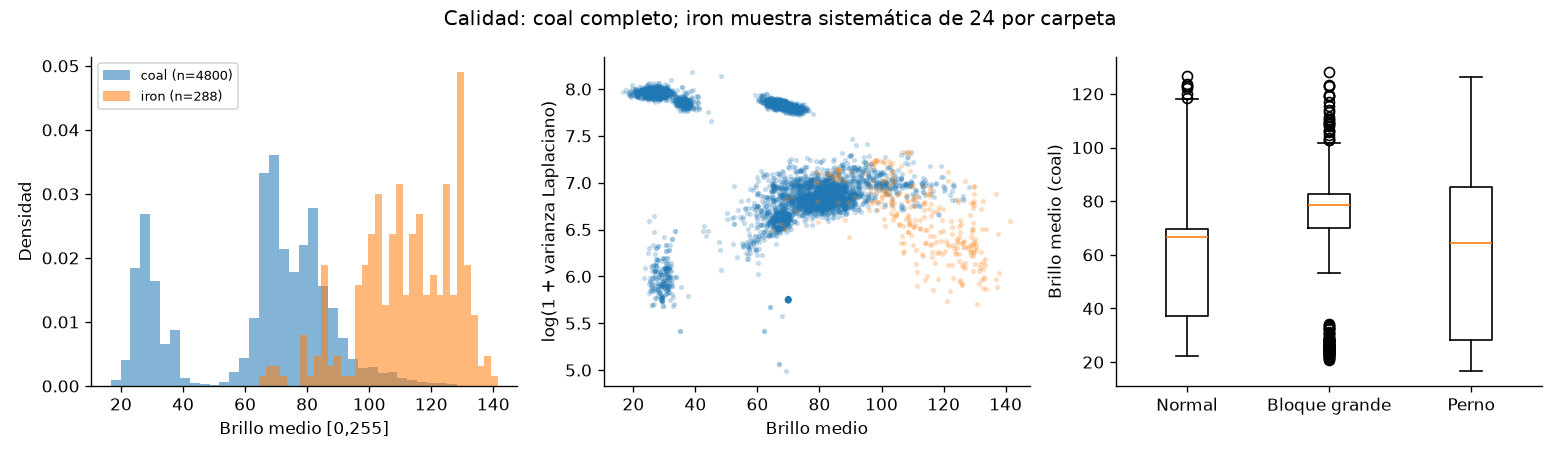

,gray_mean,gray_std,sharpness,dark_fraction,bright_fraction
gray_mean,1.00,0.79,-0.60,-0.91,0.70
gray_std,0.79,1.00,-0.58,-0.71,0.74
sharpness,-0.60,-0.58,1.00,0.58,-0.58
dark_fraction,-0.91,-0.71,0.58,1.00,-0.57
bright_fraction,0.70,0.74,-0.58,-0.57,1.00


In [5]:
variables = ['gray_mean','gray_std','sharpness','dark_fraction','bright_fraction']
summary = quality.groupby('dataset')[variables].agg(['count','mean','std','median','min','max'])
display(summary.round(3))
quartiles = quality.groupby('dataset')[variables].quantile([.25,.75]).unstack()
iqr = pd.DataFrame({v:quartiles[(v,.75)]-quartiles[(v,.25)] for v in variables})
display(iqr.rename_axis('IQR por dataset').round(3))
show(FIG/'quality.png', 1150)
display(quality[variables].corr().round(2))

**Interpretación:** las condiciones visuales difieren entre datasets y entre clases. Una correlación de métricas de calidad no identifica una causa de riesgo. El número de imágenes y la textura del mineral afectan estas descripciones; no realizamos pruebas de significancia suponiendo independencia entre fotogramas.

## 4. Limpieza y particiones: evitar resultados engañosos
La misma imagen no puede ofrecer dos clases contradictorias a un clasificador exclusivo. Se excluyeron **todos los miembros de los grupos con conflictos exactos**, sin decidir por mayoría. Después se conservó una copia de cada contenido consistente. Raw permanece intacto; el registro de exclusiones conserva cada ruta y motivo.

No se resolvieron etiquetas nuevas basándose en las predicciones del modelo. Los casos visualmente dudosos permanecen como limitación de la supervisión heredada.

,archivos
decision,
candidate,4500
exclude_conflicting_label,135
exclude_exact_copy,165


Contenidos conflictivos excluidos: 65
Candidatos únicos conservados: 4500


,,registros
issue,action,
exclude_conflicting_label,exclude_from_manifest,135
exclude_exact_copy,exclude_from_manifest,165
low_brightness_proxy,retain_if_otherwise_eligible,1076
near_pair_different_labels,same_group_no_relabel,4


label,Normal Coal Flow,Oversized Coal,Rock Bolts
split,,,
train,1052,1075,1084
val,212,216,216
test,212,217,216


,grupos proxy
split,
test,34
train,205
val,36


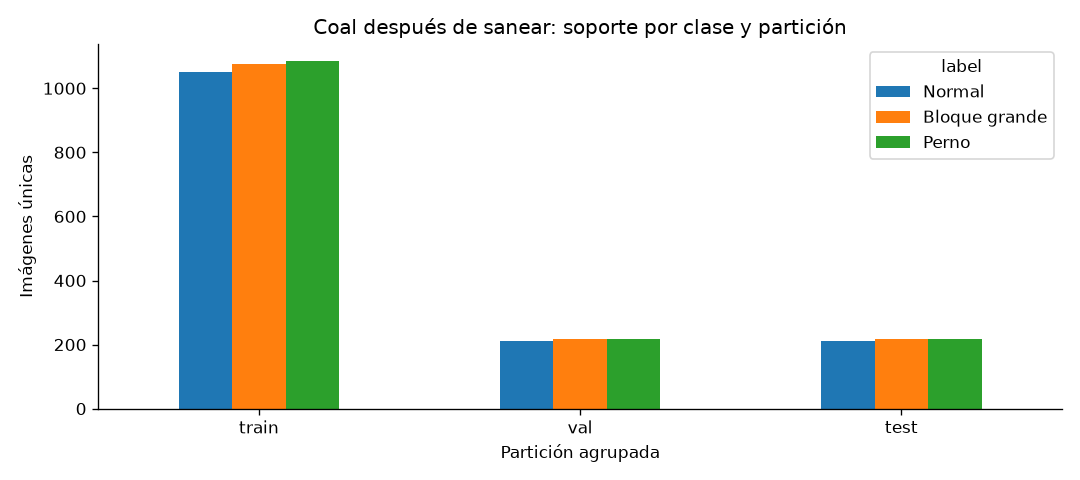

In [6]:
decisions = pd.read_csv(PROC/'annotation_decisions.csv')
display(decisions.groupby('decision').size().rename('archivos').to_frame())
print('Contenidos conflictivos excluidos:', protocol['conflicting_contents_excluded'])
print('Candidatos únicos conservados:', len(coal))
display(pd.read_csv(PROC/'quality_issues.csv').groupby(['issue','action']).size().rename('registros').to_frame())
display(pd.crosstab(coal.split, coal.label).reindex(['train','val','test']))
display(coal.groupby('split').event_group.nunique().rename('grupos proxy').to_frame())
show(FIG/'split_counts.png', 950)

**La dificultad de los vecinos visuales.** pHash y dHash solos propusieron 310.648 pares: algunos compartían fondo pero mostraban objetos distintos. Antes de modelar se añadió una confirmación por diferencia de píxeles en una ROI central de cinta a 64×64 (MAE≤2,5 y RMSE≤6, además de ambos hashes≤4). Así se conservaron 5.163 pares para agrupación, sin relabelar.

Se unieron esos grupos con ventanas de cinco minutos extraídas de HHMMSS en los nombres, sin distinguir clase ni partición original. Falta la fecha: se pueden unir capturas de días distintos y todavía pueden quedar eventos relacionados a ambos lados de una ventana. Son **275 grupos proxy, no eventos certificados**.

StratifiedGroupKFold de siete folds, semilla 42: fold 0 para test, fold 1 para validación y el resto para train. La elección se fijó antes del entrenamiento. Este es un benchmark nuevo, no el test original. Train aprende parámetros; validación permite decidir; test se consulta después de cerrar las iteraciones.

Pares confirmados por umbrales: 5163
Pares con carpetas/clases diferentes: 2
Máximo tamaño de grupo proxy: 126
Verificados: ningún hash ni grupo proxy aparece en más de un split.


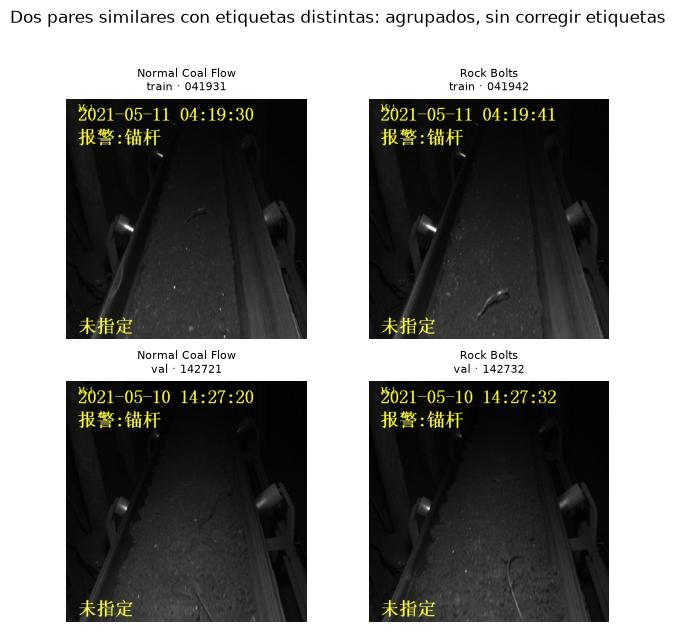

In [7]:
for field in ['sha256','visual_group','event_group','time_bin_5min']:
    assert coal.groupby(field).split.nunique().max()==1, field
assert coal.sha256.nunique()==len(coal)
assert digest(PROC/'coal_manifest.csv')==protocol['split_sha256']==selection['manifest_sha256']
edges = pd.read_csv(PROC/'near_duplicate_edges.csv')
print('Pares confirmados por umbrales:', len(edges))
print('Pares con carpetas/clases diferentes:', int((~edges.same_label).sum()))
print('Máximo tamaño de grupo proxy:', protocol['largest_proxy_group'])
print('Verificados: ningún hash ni grupo proxy aparece en más de un split.')
show(FIG/'near_cross_class.jpg', 750)

## 5. Texto sobreimpreso: una hipótesis que se prueba
El proxy detecta ≥100 píxeles amarillos en bandas superior/inferior. No transcribe el texto, no determina la clase y puede fallar. La tabla usa únicamente train y validación.

El texto puede estar asociado al origen de captura, a la fecha o a un sistema previo de alarma. No queremos presentar reconocimiento de letras como reconocimiento del objeto. Comparamos una entrada original con otra enmascarada mediante **tres rectángulos fijos normalizados**, aplicados a todas las imágenes independientemente de clase y presencia de texto. No se usa reconstrucción generativa.

,0,1,proporcion_con_proxy
label,,,
Normal Coal Flow,131,1133,0.896
Oversized Coal,1023,268,0.208
Rock Bolts,177,1123,0.864


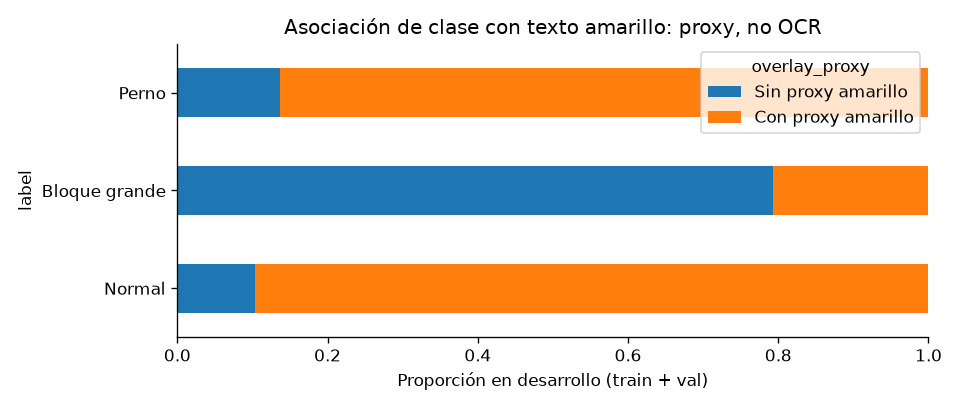

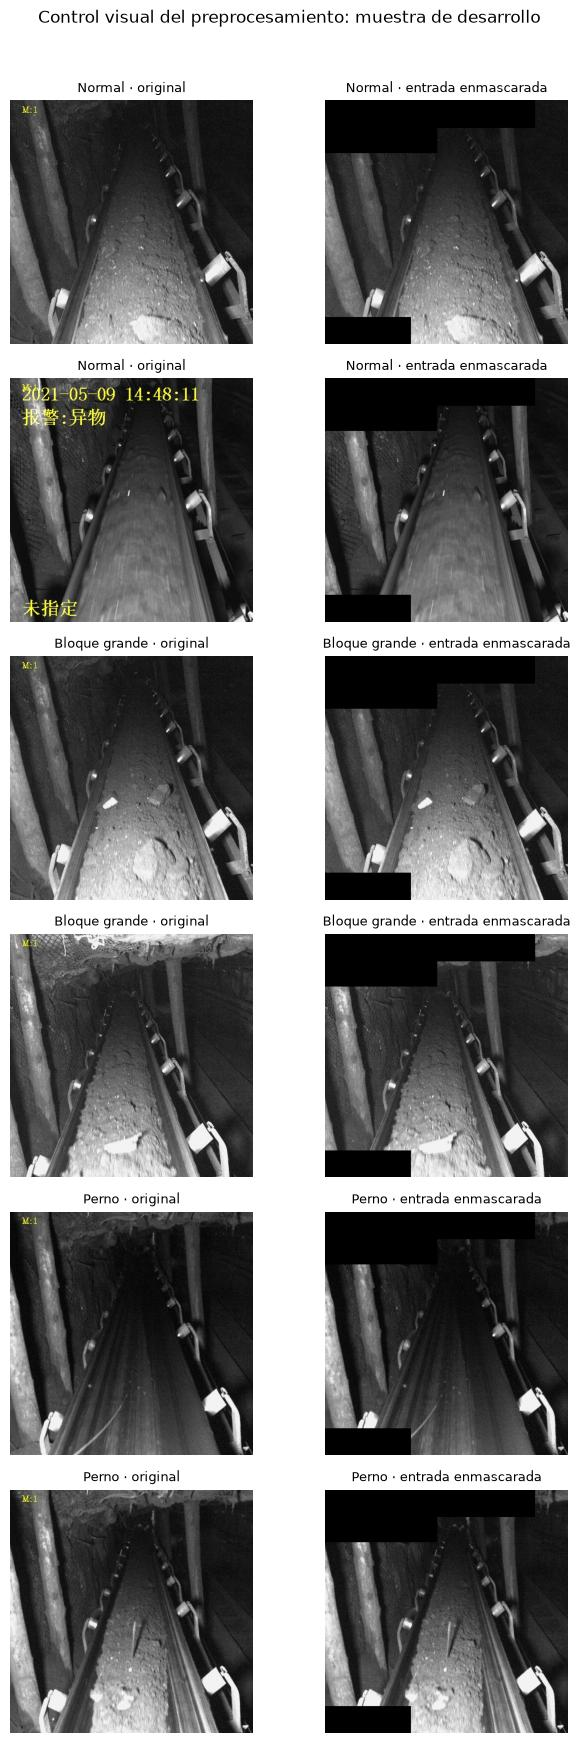

In [8]:
overlay = pd.read_csv(RESULTS/'overlay_development.csv').set_index('label')
counts = overlay.copy()
counts['proporcion_con_proxy'] = counts['1'] / (counts['0']+counts['1'])
display(counts.round(3))
show(FIG/'overlay_association.png', 900)
show(FIG/'mask_audit.jpg', 700)

**Límite de la comparación:** revisamos la máscara en una muestra de desarrollo: conserva los objetos centrales mostrados, pero puede quitar extremos de objetos que entren por esas regiones. Además de texto oculta fondo. Por ello una caída de desempeño no prueba causalmente cuánto dependía el modelo de leer el texto. Las galerías muestran la imagen fuente con la máscara aplicada. La red recibe además el redimensionado y la normalización de su configuración; por eso un detalle visible en la fuente puede perderse a 224 píxeles.

## 6. Modelos y decisiones de entrenamiento
- **M0:** prior de clases del train. No usa imágenes; entrega un piso de referencia.
- **M1:** regresión logística sobre calidad y proxy de overlay, con escalado ajustado solo en train. Es un diagnóstico de señales simples.
- **M2:** ResNet-18 preentrenada, extractor congelado y cabeza lineal de tres clases entrenada con entropía cruzada. Se almacenan características para no repetir el backbone en cada época.
- **M3 y siguientes:** ajustes decididos tras ver errores y validación; no un catálogo de arquitecturas.

“Preentrenada” significa que se reutilizan características de ImageNet, no que el modelo ya conozca nuestros pernos. Las imágenes de coal se redimensionan completas a 224×224 (o al tamaño explícito del experimento), sin recorte central, y se normalizan con los valores de esos pesos. Esto conserva el campo completo, pero puede perder detalle de objetos finos.

Los scripts eligen CUDA, MPS o CPU. En esta ejecución se utilizó MPS en Apple M1. En fine-tuning se ajustan layer4 y la cabeza, manteniendo las estadísticas BatchNorm fijas. Los resultados no se prometen idénticos bit a bit entre dispositivos. Se ejecutó una semilla por configuración: diferencias pequeñas requieren confirmación con otras semillas; el bootstrap de grupos no captura variabilidad del entrenamiento. La cabeza usa hasta 80 épocas baratas sobre embeddings cacheados y paciencia 15; el fine-tuning usa hasta 8 épocas y paciencia 3.

,kind,variant,size,seed,epochs,best_epoch,lr,augment,batch_size,device
run,,,,,,,,,,
M0_dummy,dummy,NaN,NaN,42,NaN,NaN,NaN,None,NaN,{'model': 'cpu'}
M1_quality,quality_logistic,NaN,NaN,42,NaN,NaN,NaN,None,NaN,{'model': 'cpu'}
M2_masked,frozen_head,masked,224.0,42,80.0,31.0,0.0030,None,256.0,"{'optimizer': 'cpu', 'features': 'mps'}"
M2_raw,frozen_head,raw,224.0,42,80.0,48.0,0.0030,None,256.0,"{'optimizer': 'cpu', 'features': 'mps'}"
M3_masked_ft,finetune_layer4,masked,224.0,42,8.0,3.0,0.0001,False,24.0,{'model': 'mps'}
M4_masked_jitter,finetune_layer4,masked,224.0,42,8.0,3.0,0.0001,True,24.0,{'model': 'mps'}
M5_masked_320,frozen_head,masked,320.0,42,80.0,79.0,0.0030,None,256.0,"{'optimizer': 'cpu', 'features': 'mps'}"


,run,kind,variant,train_f1,val_f1,val_balanced_accuracy,val_risk_recall,val_false_alarm_rate,seconds
0,M0_dummy,dummy,quality/prior,0.1683,0.1674,0.3333,1.0000,1.0000,0.0000
1,M1_quality,quality_logistic,quality/prior,0.8054,0.7680,0.7639,0.9699,0.2642,0.0529
2,M2_masked,frozen_head,masked,0.9350,0.8886,0.8878,0.9769,0.1792,45.9407
3,M2_raw,frozen_head,raw,0.9450,0.9042,0.9034,0.9792,0.1509,38.4601
4,M3_masked_ft,finetune_layer4,masked,0.9750,0.9205,0.9206,0.9653,0.1226,506.2712
5,M4_masked_jitter,finetune_layer4,masked,0.9750,0.9174,0.9174,0.9722,0.1321,526.0735
6,M5_masked_320,frozen_head,masked,0.9530,0.9009,0.9005,0.9583,0.1368,68.0246


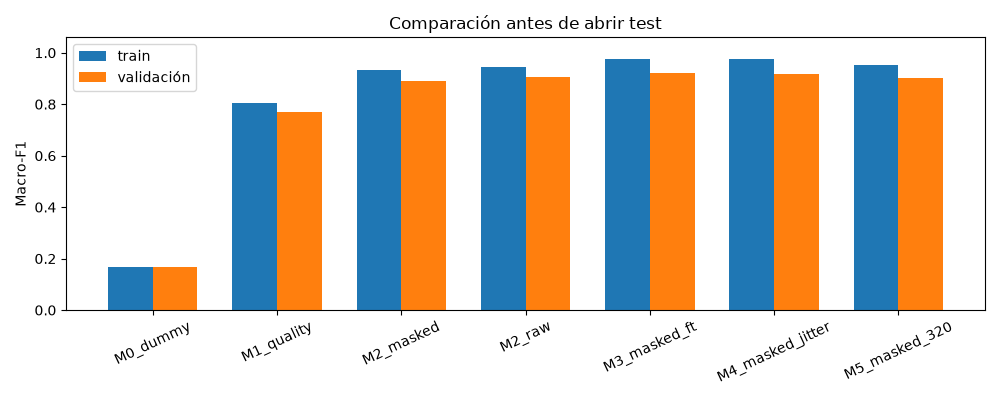

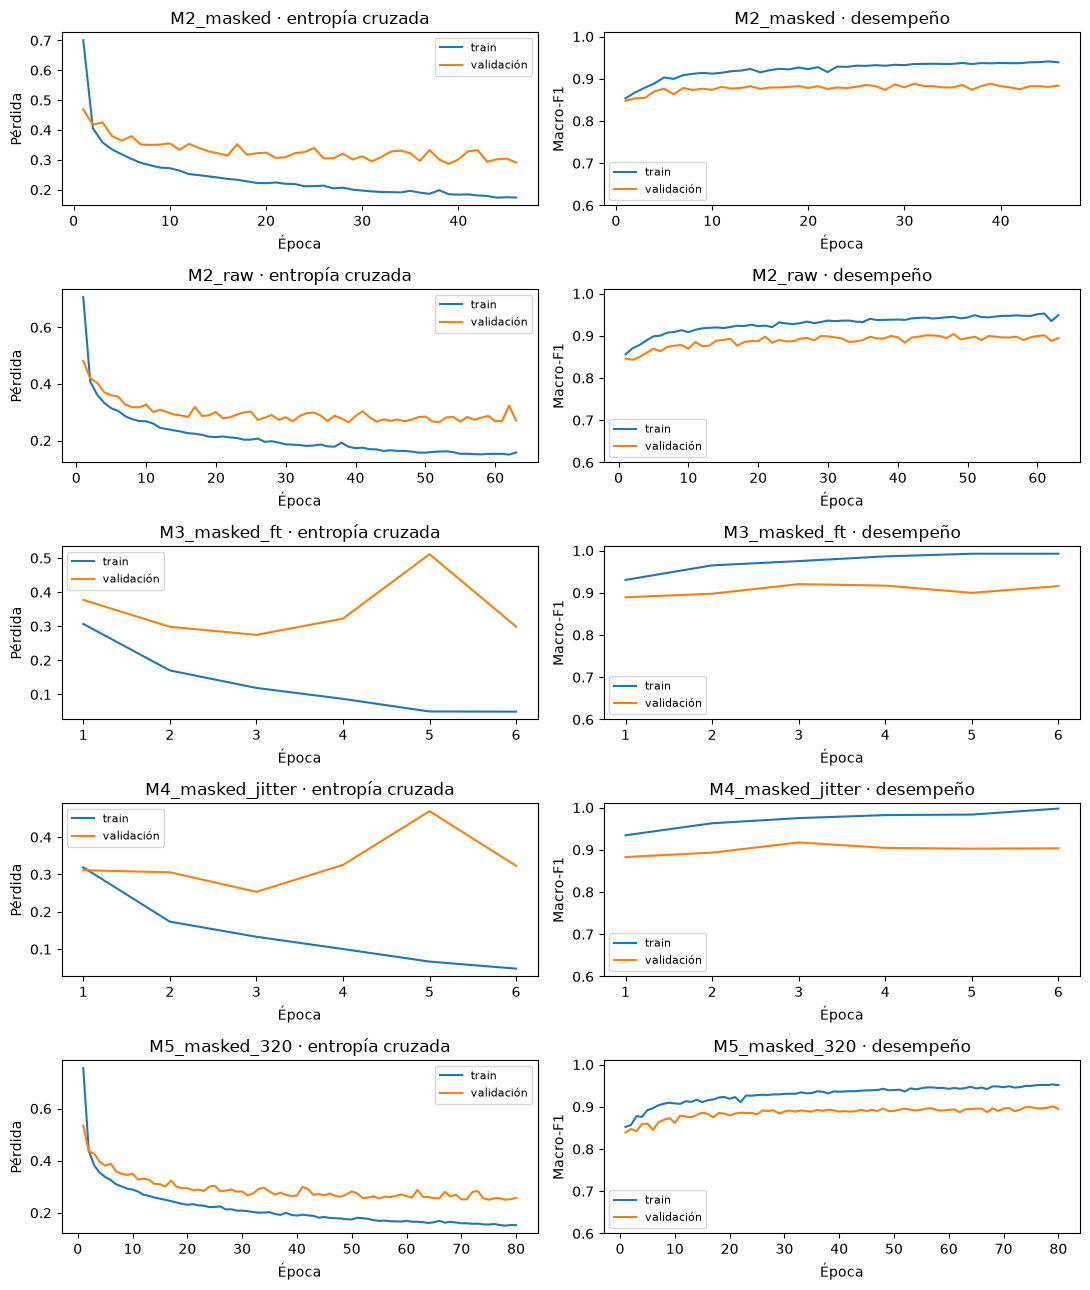

In [9]:
configs = []
for run in comparison.run:
    meta = json.loads((RESULTS/'runs'/run/'metadata.json').read_text())
    cfg = meta['config']
    configs.append({k:cfg.get(k) for k in ['kind','variant','size','seed','epochs','best_epoch','lr','augment','batch_size']}
                   | {'run':run,'device':str(meta.get('compute_devices',meta['device']))})
display(pd.DataFrame(configs).set_index('run'))
display(comparison.round(4))
show(FIG/'model_comparison.png', 1100)
show(FIG/'learning_curves.png', 1050)

## 7. Iteraciones: qué observamos y por qué cambiamos el experimento
El registro siguiente contiene hipótesis, evidencia observada y decisiones tomadas durante el trabajo. Los resultados negativos y los intentos descartados también se conservan. Todas las iteraciones de modelado se eligieron con validación; no a partir del test.

### preparation
**Hipótesis:** Los hashes globales bastan para identificar vecinos casi idénticos.

**Evidencia:** 310648 pares pHash<=4/dHash<=4; 25482 entre clases. Muestreo de 100 pares mostró MAE mediana 10.89 y RMSE 16.67 en cinta; fondos compartidos producen falsos candidatos.

**Decisión:** Rechazar agrupación por hashes solos. Confirmar ROI MAE<=2.5 y RMSE<=6, antes de entrenar. Se congelan 275 grupos proxy y split seed42; limitación de eventos no resuelta.

### M0_M1
**Hipótesis:** Brillo, textura y overlay pueden explicar una parte importante de las clases.

**Evidencia:** M0 val macro-F1=0.16744; M1 calidad=0.76799. En desarrollo, proxy de texto: normal 1133/1264, bloque 268/1291, perno 1123/1300.

**Decisión:** Comparar CNN original con otra entrenada ocultando zonas fijas del texto. No usar OCR de alarma como etiqueta.

### M2_raw
**Hipótesis:** Las características preentrenadas mejoran la referencia de calidad sin ajustar todo el backbone.

**Evidencia:** Val macro-F1=0.90418, train=0.94497. Errores de confianza alta incluyen pernos finos/oscuros y casos de etiqueta heredada discutible. Revisión visual val_errors.jpg.

**Decisión:** Ejecutar M2_masked, mismas imágenes, semilla, backbone, tamaño y entrenamiento de cabeza. La máscara también borra pequeños parches de escena; no es prueba causal pura del texto. La cabeza se optimiza en CPU sobre embeddings cacheados: se amplía el arranque del plan a un máximo de 80 épocas baratas con paciencia 15, en lugar de repetir el backbone; se conserva la mejor validación.

### M2_masked
**Hipótesis:** El clasificador conservará gran parte de la señal sin las zonas de texto.

**Evidencia:** Val macro-F1 0.88859 frente 0.90418 original (-0.01559), train 0.93498. Revisión visual: pernos delgados/oscuros y contradicciones aparentes de carpeta persisten. La máscara suprime también parte del fondo, de modo que la diferencia no identifica causalmente el texto.

**Decisión:** Investigar adaptación del último bloque sobre la variante masked para aprender detalles del mineral/perno sin recuperar los overlays. Mantener raw como referencia; no elegir por test.

### M3_masked_ft
**Hipótesis:** Adaptar layer4 al dominio puede recuperar detalles sin restaurar las zonas de texto.

**Evidencia:** Mejor época 3: macro-F1 val 0.92052 frente a 0.88859 con extractor congelado (+0.03193), train 0.97504. Épocas 4–6: train sube hasta 0.99251 pero val no supera el máximo; early stopping tras 3 sin mejora.

**Decisión:** Conservar checkpoint de época 3 y no el último. Revisar errores y probar brightness/contrast jitter ±15%, con el mismo parent M2_masked, tasas, tamaño, semilla y máximo de épocas. Único cambio de tratamiento: augmentation.

### M4_masked_jitter
**Hipótesis:** Variar moderadamente brillo y contraste de train reducirá el sobreajuste del último bloque.

**Evidencia:** Mejor época 3: val macro-F1=0.91737, train=0.97504; M3 sin jitter=0.92052. Parada en época 6; train final llega a 0.99751 sin mejora sostenida de validación. En esta semilla no se observa ventaja del jitter. Persisten pernos finos en escenas oscuras y posibles problemas de etiqueta.

**Decisión:** No adoptar jitter por defecto. Probar una última hipótesis acotada: tamaño 320 en el extractor congelado, comparándolo con M2_masked de 224; mismo head, semilla y presupuesto. Si no mejora, cerrar la etapa y priorizar adjudicación de etiquetas/más diversidad en el siguiente hito.

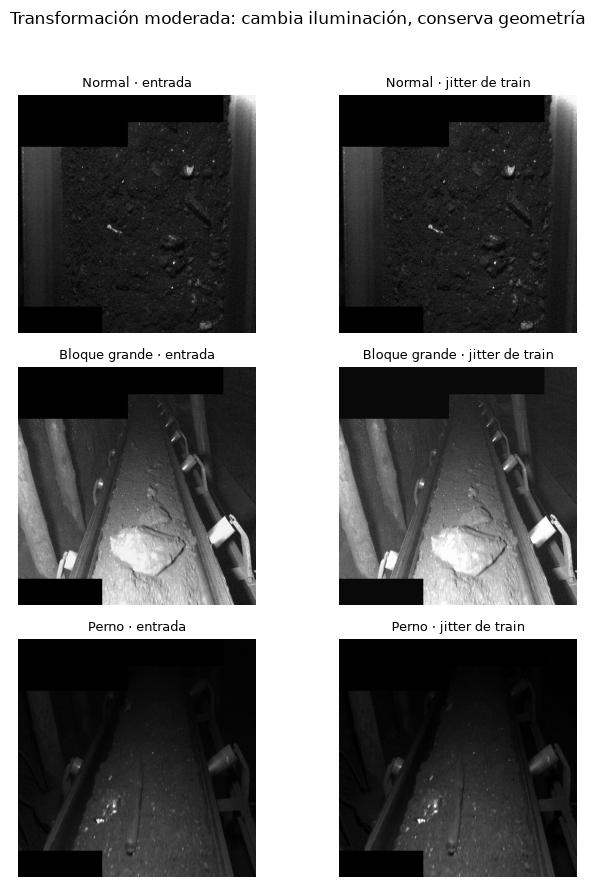

In [10]:
show(FIG/'augmentation_audit.jpg', 700)

### M5_masked_320
**Hipótesis:** Aumentar resolución permitirá conservar más detalle de pernos finos con el extractor congelado.

**Evidencia:** Val macro-F1=0.90092, train=0.95299. Mejora +0.01233 respecto a M2_masked de 224 (0.88859), pero no supera M3_masked_ft de 224 (0.92052). La extracción tardó aproximadamente 63 s frente a 42 s de masked224. Revisión de errores: persisten escenas oscuras/otra vista y etiquetas discutibles.

**Decisión:** Cerrar esta etapa con 7 ejecuciones y seleccionar M3_masked_ft por la mayor macro-F1 de validación. Resolución ayuda moderadamente al extractor fijo, pero no justifica reemplazar la adaptación en este estudio. Fine-tuning a mayor resolución, más semillas y adjudicación de etiquetas quedan como siguientes experimentos; no se abre otra búsqueda extensa ni se usa test para ajustar.

## 8. Selección final y evaluación reservada
La selección se guarda antes de abrir el test. Se utiliza macro-F1 de validación según el criterio registrado. La salida de alarma suma las probabilidades de bloque y perno; su umbral se elige maximizando F2 en validación, ponderando más la sensibilidad. Es una elección exploratoria, no una función de costos acordada con una planta.

Macro-F1 promedia el F1 de las tres clases; balanced accuracy promedia sus recalls. Para riesgo, falsa alarma significa una imagen etiquetada normal que genera alarma. No podemos convertir esa tasa en alarmas por hora sin frecuencia de captura y lógica temporal.

,selección fijada antes del test
run,M3_masked_ft
criterion,highest validation macro-F1; deterministic lex...
val_macro_f1,0.92052
risk_threshold,0.019967
threshold_criterion,"maximum F2 on validation; exploratory, no oper..."
validation_f2,0.978656
manifest_sha256,f3e452c37768a161445b466760147edbbe610d7185b77f...
weights_sha256,dcc974b0f5cda6c5bf6b27389b50e4701ea2cd11478529...
candidate_runs,"[M0_dummy, M1_quality, M2_masked, M2_raw, M3_m..."


,macro_f1,balanced_accuracy,accuracy
modelo,,,
M0_dummy,0.1672,0.3333,0.3349
M3_masked_ft,0.9319,0.9317,0.9318


,precision,recall,f1-score,support
Normal Coal Flow,0.9515,0.9245,0.9378,212.0
Oversized Coal,0.9115,0.9493,0.9300,217.0
Rock Bolts,0.9343,0.9213,0.9277,216.0
macro avg,0.9324,0.9317,0.9319,645.0
weighted avg,0.9323,0.9318,0.9318,645.0


,alarma en test al umbral fijado
threshold,0.019967
recall,0.997691
precision,0.947368
false_alarm_rate,0.113208
average_precision,0.994811
tp,432.000000
fn,1.000000
fp,24.000000
tn,188.000000


,"inferencia local por lotes, no latencia de planta"
seconds,6.178849
n,645
batch_size,48
device,mps
includes_io,True


IC exploratorio 95% macro-F1, bootstrap por grupos proxy: [0.8679651051976817, 0.9580580475821121]
Grupos proxy de test: 34


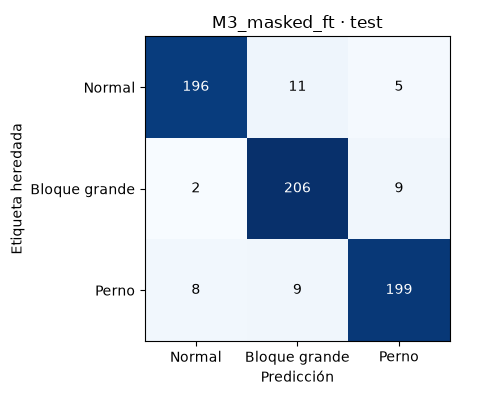

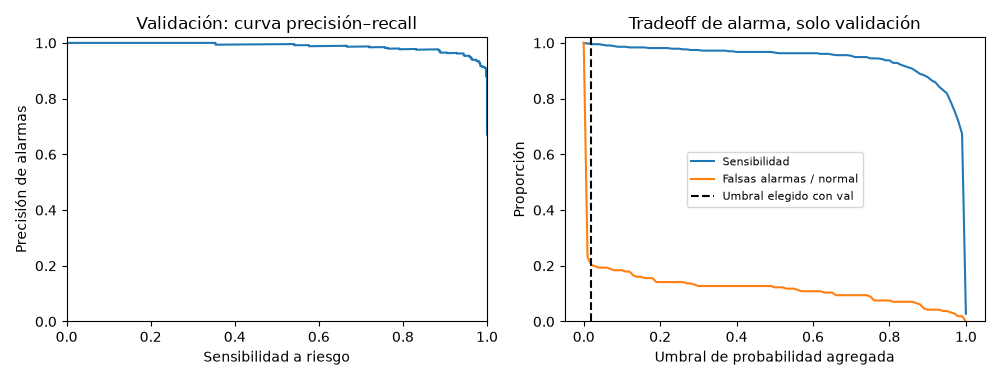

In [11]:
display(pd.Series(selection, name='selección fijada antes del test').to_frame())
test_metrics = final['test']
dummy_metrics = final['dummy_test']
display(pd.DataFrame([
    {'modelo':'M0_dummy','macro_f1':dummy_metrics['macro_f1'],'balanced_accuracy':dummy_metrics['balanced_accuracy'],'accuracy':dummy_metrics['accuracy']},
    {'modelo':selected,'macro_f1':test_metrics['macro_f1'],'balanced_accuracy':test_metrics['balanced_accuracy'],'accuracy':test_metrics['accuracy']}
]).set_index('modelo').round(4))
report = {k:v for k,v in test_metrics['report'].items() if isinstance(v,dict)}
display(pd.DataFrame(report).T.round(4))
display(pd.Series(test_metrics['risk'], name='alarma en test al umbral fijado').to_frame())
display(pd.Series(final['inference'], name='inferencia local por lotes, no latencia de planta').to_frame())
print('IC exploratorio 95% macro-F1, bootstrap por grupos proxy:', test_metrics['macro_f1_group_bootstrap_95'])
print('Grupos proxy de test:', test_metrics['proxy_groups'])
show(run_dir/'test_confusion.png', 650)
show(FIG/'alarm_tradeoff.png', 1050)

In [12]:
test_predictions = pd.read_csv(run_dir/'test_predictions.csv')
recomputed = summarize(test_predictions.target, test_predictions[['p0','p1','p2']].to_numpy(), selection['risk_threshold'])
assert abs(recomputed['macro_f1']-test_metrics['macro_f1']) < 1e-12
assert recomputed['confusion']==test_metrics['confusion']
assert recomputed['risk']['tp']==test_metrics['risk']['tp']
assert len(test_predictions)==len(coal[coal.split=='test'])
weight_path = PROJECT_ROOT/'data/weights/patrick_v1'/f'{selected}.pt'
assert digest(weight_path)==selection['weights_sha256']
print('Métricas reconstruidas desde predicciones; manifest y checkpoint coinciden con la selección.')

Métricas reconstruidas desde predicciones; manifest y checkpoint coinciden con la selección.


**Resultado observado:** M3_masked_ft obtuvo macro-F1 **0.932** y balanced accuracy **0.932** en las 645 imágenes de test. Al umbral de alarma fijado con validación, detectó 432 de 433 imágenes de riesgo y activó 24 falsas alarmas entre 212 imágenes normales.

El intervalo por bootstrap usa grupos proxy: describe variabilidad interna bajo esa agrupación, no incertidumbre de desempeño en otra planta. Las etiquetas heredadas y el número limitado de grupos restringen la conclusión. El test no se empleó para volver a ajustar después de conocer este resultado.

**El balance y la prevalencia importan.** En este test cerca de dos tercios de las imágenes son de riesgo, por construcción de las clases. Por eso su precisión de alarmas no se puede trasladar directamente a una planta donde los incidentes podrían ser mucho menos frecuentes.

Como ejemplo matemático, no como estimación de una planta: si solo 1% de las imágenes tuviera riesgo y se mantuvieran exactamente las mismas sensibilidad y tasa de falsas alarmas, la precisión esperada de las alarmas se calcula con la fórmula siguiente. Esa hipótesis de tasas constantes tampoco está demostrada fuera de estos datos.

In [13]:
hypothetical_prevalence = .01  # Escenario ilustrativo, no prevalencia medida.
sensitivity = test_metrics['risk']['recall']
false_alarm_rate = test_metrics['risk']['false_alarm_rate']
illustrative_precision = (sensitivity*hypothetical_prevalence /
                         (sensitivity*hypothetical_prevalence + false_alarm_rate*(1-hypothetical_prevalence)))
print(f'Escenario hipotético con 1% de riesgo: precisión de alarmas ≈ {illustrative_precision:.1%}.')
print('Esto explica por qué una alta sensibilidad no basta para declarar un sistema operacional.')

Escenario hipotético con 1% de riesgo: precisión de alarmas ≈ 8.2%.
Esto explica por qué una alta sensibilidad no basta para declarar un sistema operacional.


## 9. Errores, confianza y dificultades que quedan
Las galerías priorizan errores de alta confianza, con representación de clases. Son una muestra dirigida para diagnóstico, no una muestra para estimar frecuencias.

Entre los errores de desarrollo observamos pernos finos sobre mineral oscuro, cambios de vista y ejemplos donde la etiqueta de carpeta parece discutible. Una predicción plausible no autoriza a corregir la etiqueta automáticamente. Para una siguiente versión hace falta adjudicación con reglas explícitas y revisión independiente, manteniendo congelada la evaluación de esta versión.

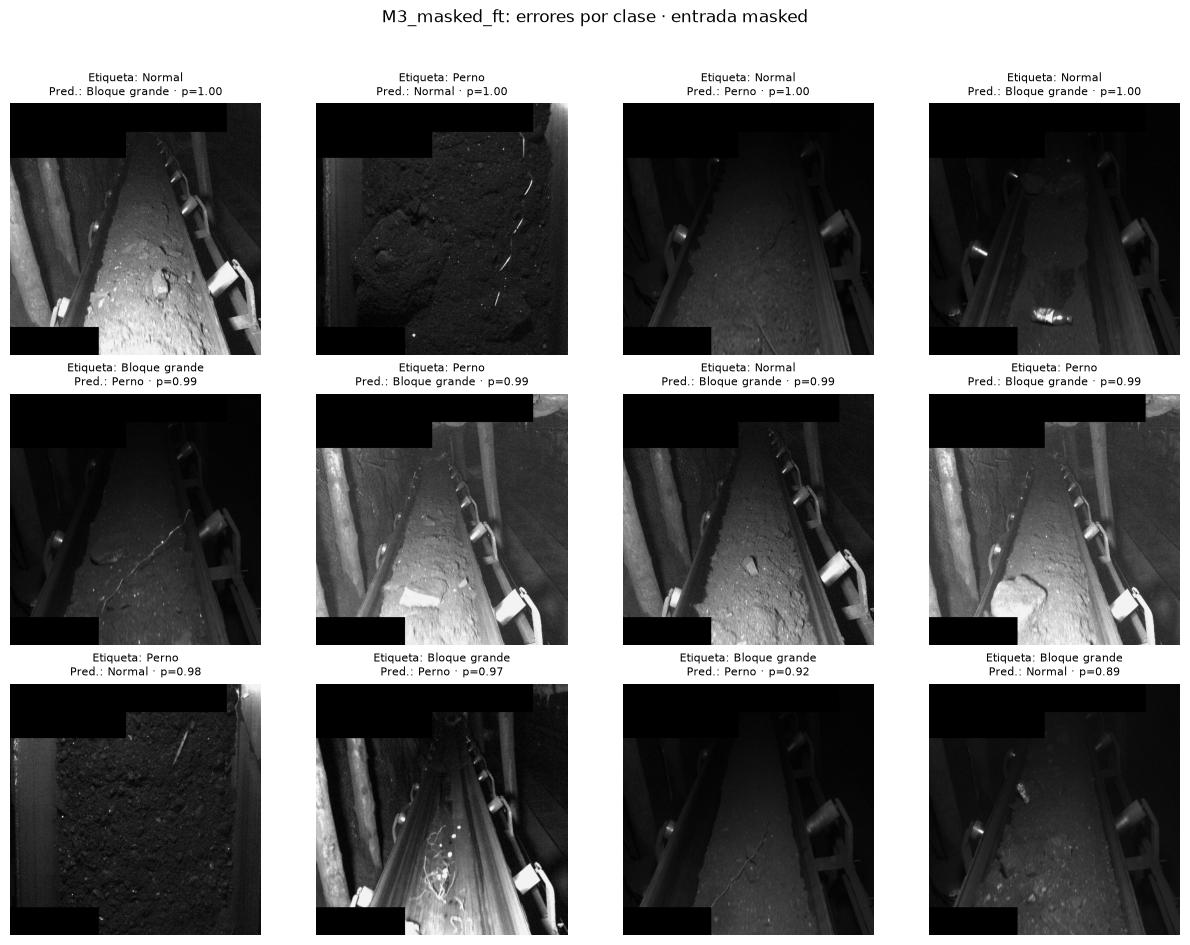

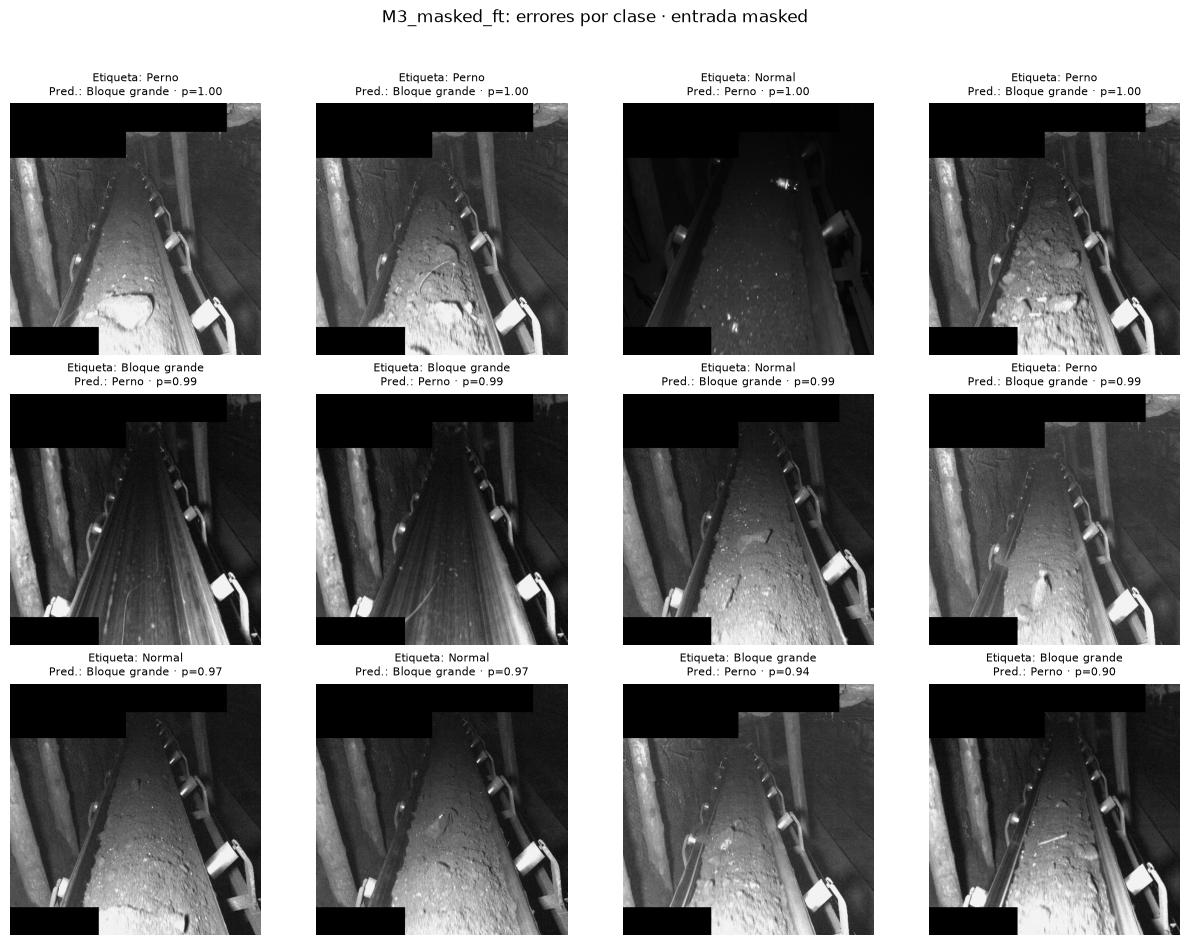

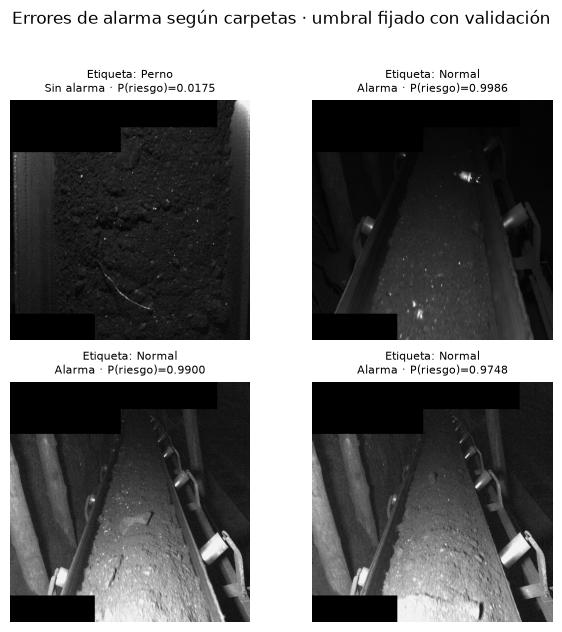

,overlay_proxy,n,accuracy,macro_f1
0,0,219,0.9452,0.8891
1,1,425,0.9082,0.8905


,Normal,Bloque grande,Perno
Normal,196,11,5
Bloque grande,2,206,9
Perno,8,9,199


In [14]:
if (run_dir/'val_errors.jpg').exists():
    show(run_dir/'val_errors.jpg', 1100)
if (run_dir/'test_errors.jpg').exists():
    show(run_dir/'test_errors.jpg', 1100)
show(FIG/'alarm_errors.jpg', 750)
display(pd.read_csv(run_dir/'val_overlay_slices.csv').round(4))
error_counts = pd.crosstab(test_predictions.target, test_predictions.prediction).reindex(index=[0,1,2],columns=[0,1,2],fill_value=0)
error_counts.index = SPANISH; error_counts.columns = SPANISH
display(error_counts)

La galería de alarma separa el objetivo binario de la clasificación de tres clases. Confundir bloque y perno puede contar como error de clase y aun activar correctamente una alarma. La única omisión de riesgo muestra una línea delgada y curva sobre mineral oscuro; en los ejemplos de falsa alarma también hay etiquetas heredadas que conviene adjudicar. Esta es inspección posterior del test para explicar límites, **sin modificar el modelo ni el umbral**.

## 10. Cargar el modelo y reproducir una predicción
El checkpoint conserva pesos, orden de clases y transformación. Usar el mismo preprocesamiento importa tanto como cargar los pesos. Este ejemplo reconstruye una predicción ya guardada como comprobación; no abre otro experimento ni selecciona por test.

In [15]:
import torch
from modeling import build_model, CoalImages, DEVICE
checkpoint = torch.load(weight_path, map_location='cpu', weights_only=True)
model = build_model(pretrained=False)
model.load_state_dict(checkpoint['state_dict'])
model = model.to(DEVICE).eval()
cfg = checkpoint['config']
example = coal.set_index('path').loc[[test_predictions.path.iloc[0]]].reset_index()
x, _ = CoalImages(example, cfg['variant'], cfg['size'])[0]
with torch.inference_mode():
    probabilities = model(x.unsqueeze(0).to(DEVICE)).softmax(1).cpu().numpy()[0]
assert np.allclose(probabilities, test_predictions.iloc[0][['p0','p1','p2']].to_numpy(dtype=float), atol=5e-4)
display(pd.Series(probabilities, index=CLASSES, name='probabilidad').to_frame())
print('Etiqueta heredada:', example.label.iloc[0])
print('Predicción:', CLASSES[int(probabilities.argmax())])
print('Entrada:', cfg['variant'], cfg['size'], '×', cfg['size'])

,probabilidad
Normal Coal Flow,0.999976
Oversized Coal,0.000003
Rock Bolts,0.000020


Etiqueta heredada: Normal Coal Flow
Predicción: Normal Coal Flow
Entrada: masked 224 × 224


## 11. Qué presentar y qué desarrollar después
**La etapa temprana está centrada en coal.** Podemos exponer la auditoría, el problema de los fondos para agrupar imágenes, la referencia de calidad, el aporte de la CNN, el experimento con texto, los ajustes ejecutados, la selección por validación y los errores finales.

**Iron:** el siguiente paso concreto es etiquetar una muestra temporal por presencia real, manteniendo casos inciertos y cinta vacía separados. Solo después compararíamos coal, iron y ambos, evaluando por dominio. No hay evidencia aquí de que el modelo sirva para iron, otra cámara o cualquier objeto extraño.

**Sintéticos:** una composición de objetos recortados y fondos de train sería un experimento posterior para cubrir una carencia concreta. No arregla etiquetas ni prueba generalización. Compararíamos real frente a real+sintético sobre la misma evaluación real.

**Bounding boxes:** se requieren cuando definamos una tarea supervisada de localización. El primer piloto usaría imágenes diversas por evento con todos los objetos objetivo anotados; las imágenes normales verificadas no llevan una caja ficticia. Esta entrega clasifica imágenes y no estima coordenadas.

Las extensiones están **aplazadas con justificación**, no ejecutadas. No se generan tablas de resultados ficticios de iron, sintéticos o detectores.

In [16]:
display(pd.DataFrame([
    {'línea':'Exploración coal/iron','estado':'Ejecutada','evidencia':'Inventario, calidad, galerías y resúmenes'},
    {'línea':'Limpieza y particiones coal','estado':'Ejecutada con límites','evidencia':'Decisiones, hashes y grupos proxy'},
    {'línea':'Referencias y CNN','estado':'Ejecutada','evidencia':'Comparación, curvas, checkpoints y predicciones'},
    {'línea':'Tratamiento del texto y ajustes','estado':'Ejecutada','evidencia':'Diario de iteraciones y métricas de validación'},
    {'línea':'Supervisión y modelo conjunto iron','estado':'Aplazada','evidencia':'Faltan etiquetas verificadas y eventos de evaluación'},
    {'línea':'Sintéticos y detector con cajas','estado':'Aplazada','evidencia':'Requieren objetivo/anotaciones y evaluación real'}
]))

,línea,estado,evidencia
0,Exploración coal/iron,Ejecutada,"Inventario, calidad, galerías y resúmenes"
1,Limpieza y particiones coal,Ejecutada con límites,"Decisiones, hashes y grupos proxy"
2,Referencias y CNN,Ejecutada,"Comparación, curvas, checkpoints y predicciones"
3,Tratamiento del texto y ajustes,Ejecutada,Diario de iteraciones y métricas de validación
4,Supervisión y modelo conjunto iron,Aplazada,Faltan etiquetas verificadas y eventos de eval...
5,Sintéticos y detector con cajas,Aplazada,Requieren objetivo/anotaciones y evaluación real


In [17]:
iron_candidates = pd.read_csv(PROC/'iron_annotation_candidates.csv', keep_default_na=False)
assert (iron_candidates.review_status=='unreviewed').all()
assert (iron_candidates.verified_label=='').all()
print('Próximo paso preparado:', len(iron_candidates), 'candidatos temporales de iron, todos sin revisar ni etiquetar.')
display(iron_candidates.head(3))

Próximo paso preparado: 288 candidatos temporales de iron, todos sin revisar ni etiquetar.


,path,group,frame_index,selection_reason,review_status,verified_label,notes
0,iron/image-files/boardcamera_iron_ore/5726-boa...,iron/image-files/boardcamera_iron_ore,5726,24_equally_spaced_positions_in_numeric_frame_o...,unreviewed,,
1,iron/image-files/boardcamera_iron_ore/5975-boa...,iron/image-files/boardcamera_iron_ore,5975,24_equally_spaced_positions_in_numeric_frame_o...,unreviewed,,
2,iron/image-files/boardcamera_iron_ore/6225-boa...,iron/image-files/boardcamera_iron_ore,6225,24_equally_spaced_positions_in_numeric_frame_o...,unreviewed,,


## 12. Reproducibilidad y fuentes
Los comandos y dependencias están en `README.md`. `study_data.py` produce inventario/EDA; `modeling.py` ejecuta referencias, cabezas y fine-tuning y sella el test; `build_notebook.py` construye esta exposición; `verify_study.py` audita resultados y entradas. `PROGRESO.md` registra el estado del trabajo y `experiment_journal.json` conserva las hipótesis.

Cada ejecución tiene configuración, versiones, hash del manifiesto y fuentes preservadas. Los artefactos son locales; no se publicaron datos ni se hicieron commits/push. Las instrucciones de Colab son orientación y no una integración verificada.

Fuentes técnicas primarias:
- [Transferencia de aprendizaje en PyTorch](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html).
- [Pesos y normalización de ResNet-18](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html).
- [Particiones con StratifiedGroupKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html).

La evidencia del proyecto procede de los archivos locales y de los experimentos guardados; las fuentes explican las técnicas, no certifican nuestros resultados.